# Instacart Market Basket Analysis 

### 📥 Dataset Download Instructions for Google Colab
If you are running this notebook on **Google Colab** and need to download the Instacart dataset, simply **double-click** this cell (or create a code cell right below it), paste the download code, and execute it.

import os
import json

# 1. Set up Kaggle credentials automatically using your provided key
kaggle_creds = {"username": "yassine-barigou", "key": "KGAT_40d0ab2adde1fa5f9b69c27873c767c6"}
# (If your username is different, make sure to use your exact Kaggle account username)

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump(kaggle_creds, f)

# Set correct file permissions
os.chmod('/root/.kaggle/kaggle.json', 600)

# 2. Install kaggle library if not already installed
!pip install -q kaggle

# 3. Download the Instacart dataset directly into your folder
!kaggle datasets download -d psparks/instacart-market-basket-analysis

# 4. Unzip all the CSV files (order_products__prior.csv, products.csv, orders.csv, etc.)
import zipfile
with zipfile.ZipFile('instacart-market-basket-analysis.zip', 'r') as zip_ref:
    zip_ref.extractall('./')

print("Dataset downloaded and extracted successfully!")


## Why Apache Spark Instead of Pandas?

We initially faced RAM limitations when processing our dataset using Pandas, which made data processing difficult. Therefore, we switched to **Apache Spark**, taking advantage of its distributed computing, data partitioning, and parallel processing capabilities to handle larger datasets more efficiently.


In [2]:
from pyspark.sql import SparkSession
#!pip install pyspark
# Initialize Spark Session
spark = SparkSession.builder \
    .appName("InstacartAssociationRules") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("Spark Session created successfully!")
spark

Spark Session created successfully!


In [3]:
order_products = spark.read.option("header","True").option("inferSchema","True").csv("order_products__prior.csv")
products = spark.read.option("header","True").option("inferSchema","True").csv("products.csv")



print(f"Total rows in order_products: {order_products.count():,}")
print(f"Total rows in products: {products.count():,}")

Total rows in order_products: 32,434,489
Total rows in products: 49,688


In [4]:
order_products.show(5)
products.show(5,truncate=False)

+--------+----------+-----------------+---------+
|order_id|product_id|add_to_cart_order|reordered|
+--------+----------+-----------------+---------+
|       2|     33120|                1|        1|
|       2|     28985|                2|        1|
|       2|      9327|                3|        0|
|       2|     45918|                4|        1|
|       2|     30035|                5|        0|
+--------+----------+-----------------+---------+
only showing top 5 rows
+----------+-----------------------------------------------------------------+--------+-------------+
|product_id|product_name                                                     |aisle_id|department_id|
+----------+-----------------------------------------------------------------+--------+-------------+
|1         |Chocolate Sandwich Cookies                                       |61      |19           |
|2         |All-Seasons Salt                                                 |104     |13           |
|3         |Robu

In [5]:
merged_data = order_products.join(products,on="product_id",how = "inner")
merged_data.show(5,truncate=False)

+----------+--------+-----------------+---------+---------------------+--------+-------------+
|product_id|order_id|add_to_cart_order|reordered|product_name         |aisle_id|department_id|
+----------+--------+-----------------+---------+---------------------+--------+-------------+
|33120     |2       |1                |1        |Organic Egg Whites   |86      |16           |
|28985     |2       |2                |1        |Michigan Organic Kale|83      |4            |
|9327      |2       |3                |0        |Garlic Powder        |104     |13           |
|45918     |2       |4                |1        |Coconut Butter       |19      |13           |
|30035     |2       |5                |0        |Natural Sweetener    |17      |13           |
+----------+--------+-----------------+---------+---------------------+--------+-------------+
only showing top 5 rows


In [6]:
merged_data.createOrReplaceTempView("merged_data")
total_transactions = spark.sql("select count(distinct(order_id)) from merged_data")
total_transactions.show(truncate=False)

+------------------------+
|count(DISTINCT order_id)|
+------------------------+
|3214874                 |
+------------------------+



In [7]:
clean_data = spark.sql("select order_id,product_name from merged_data").dropna()
clean_data.show(5,truncate=False)

+--------+---------------------+
|order_id|product_name         |
+--------+---------------------+
|2       |Organic Egg Whites   |
|2       |Michigan Organic Kale|
|2       |Garlic Powder        |
|2       |Coconut Butter       |
|2       |Natural Sweetener    |
+--------+---------------------+
only showing top 5 rows


In [8]:
import pyspark.sql.functions as F
from pyspark.ml.fpm import FPGrowth
transactions = clean_data.groupBy("order_id").agg(F.collect_set("product_name").alias("items"))
transactions.show(truncate=False)

+--------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|order_id|items                                                                                                                                                                                                                                                                                                                                                                                         

In [10]:
import pyspark.sql.functions as F
import pandas as pd

# 1. Add a new column to calculate the size of each basket
basket_sizes_df = transactions.withColumn("basket_size", F.size(F.col("items")))

# 2. Compute all summary metrics using Spark's built-in aggregations
summary_metrics = basket_sizes_df.agg(
    F.count("*").alias("Total Transactions"),
    F.max("basket_size").alias("Maximum Basket Size"),
    F.min("basket_size").alias("Minimum Basket Size"),
    F.round(F.avg("basket_size"), 2).alias("Average Basket Size")
).collect()[0] # .collect() pulls just this single row of summary numbers back to driver

# Get distinct items count from your clean_data
distinct_items_count = clean_data.select("product_name").distinct().count()

# 3. Build the final summary table in Pandas using the lightweight aggregated results
summary_df = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Distinct Items",
        "Minimum Basket Size",
        "Average Basket Size",
        "Maximum Basket Size"
    ],
    "Value": [
        summary_metrics["Total Transactions"],
        distinct_items_count,
        summary_metrics["Minimum Basket Size"],
        summary_metrics["Average Basket Size"],
        summary_metrics["Maximum Basket Size"]
    ]
})

display(summary_df)

,Metric,Value
0,Total Transactions,3214874.00
1,Distinct Items,49677.00
2,Minimum Basket Size,1.00
3,Average Basket Size,10.09
4,Maximum Basket Size,145.00


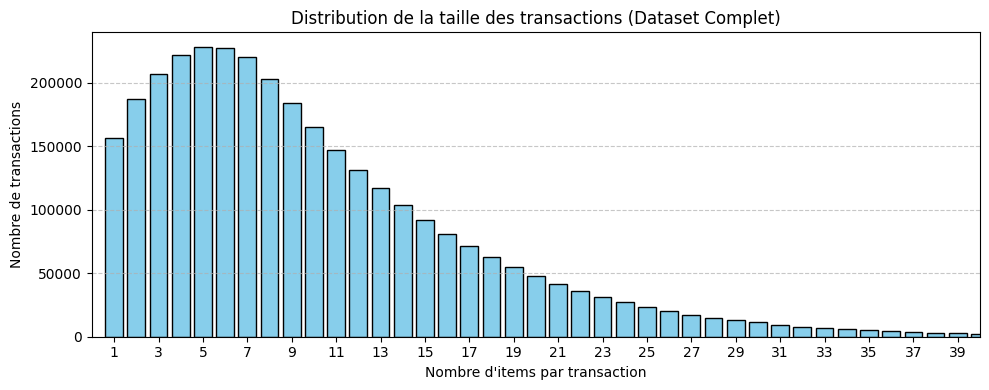

In [ ]:
import matplotlib.pyplot as plt
import pyspark.sql.functions as F

basket_sizes_df = transactions.withColumn("basket_size", F.size(F.col("items")))


size_counts_df = basket_sizes_df.groupBy("basket_size") \
                                .count() \
                                .orderBy("basket_size") \
                                .toPandas() # Only a few dozen rows are brought to local Pandas (one row per unique basket size length)

tailles_paniers_vals = size_counts_df["basket_size"].tolist()
nombre_transactions = size_counts_df["count"].tolist()

plt.figure(figsize=(10, 4))
plt.bar(tailles_paniers_vals, nombre_transactions, width=0.8, align="center", color='skyblue', edgecolor='black')
plt.title("Distribution de la taille des transactions (Dataset Complet)")
plt.xlabel("Nombre d'items par transaction")
plt.ylabel("Nombre de transactions")

# Zoom in on a clean readable range (e.g., baskets from 1 to 40 items)
plt.xlim(0, 40)
plt.xticks(range(1, 41, 2))

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Take a safe sample of 1,000 transaction baskets from Spark and bring them locally to Python
sample_baskets = transactions.limit(1000).select("items").rdd.flatMap(lambda x: x).collect()

from mlxtend.preprocessing import TransactionEncoder
import pandas as pd

te = TransactionEncoder()
tableau_encode = te.fit(sample_baskets).transform(sample_baskets)
df_basket = pd.DataFrame(tableau_encode, columns=te.columns_)

df_basket.head(10).to_excel("dataset2.xlsx")
display(df_basket.head(10))
print("Dimensions de la matrice (Échantillon 1000 lignes) :", df_basket.shape)

,"""12"""" Aluminium Foil""","""4.5"""" Street Taco Flour Tortilla""","""The """"World's Best\"""" Veggie Burger""",0% Fat Free Organic Milk,0% Greek Strained Yogurt,1 Apple + 1 Mango Fruit Bar,1 Liter,1% Low Fat Milk,1% Lowfat Milk,100 Calorie Per Bag Popcorn,...,Zero Soda,Zero Ultra Energy Drink,Zero calorie Sport Drink,Zesta Original Saltine Crackers,Zinfandel,Zucchini Banana & Amaranth Organic Baby Food,for Tots Apple Juice,of Hanover 100 Calorie Pretzels Mini,with Crispy Almonds Cereal,with Xylitol Minty Sweet Twist 18 Sticks Sugar Free Gum
0,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Dimensions de la matrice (Échantillon 1000 lignes) : (1000, 4482)


In [ ]:
import pyspark.sql.functions as F
import matplotlib.pyplot as plt

# 1. Calculate item frequencies across the ENTIRE dataset using Spark
# (Group by product_name and count how many orders contain each item)
item_counts_df = clean_data.groupBy("product_name") \
                           .count() \
                           .withColumnRenamed("count", "Frequence")

# 2. Get the total unique transaction count dynamically from your dataset
total_transactions_count = transactions.count()

# 3. Add the Support column: Support = Frequence / Total Transactions
item_freq_support_df = item_counts_df.withColumn("Support", F.col("Frequence") / total_transactions_count) \
                                     .orderBy(F.desc("Frequence"))

# 4. Bring ONLY the top results (or full sorted list if lightweight) to Pandas for display
# To match your teacher's exact display requirement, we collect to a Pandas DataFrame:
frequences_items = item_freq_support_df.toPandas()

# Display the full frequency & support table
display(frequences_items)



,product_name,Frequence,Support
0,Banana,472565,1.469933e-01
1,Bag of Organic Bananas,379450,1.180295e-01
2,Organic Strawberries,264683,8.233075e-02
3,Organic Baby Spinach,241921,7.525054e-02
4,Organic Hass Avocado,213584,6.643620e-02
...,...,...,...
49672,Cld/Flu Van Chrry,1,3.110542e-07
49673,Miss Treated Conditioner,1,3.110542e-07
49674,Piquillo & Jalapeno Bruschetta,1,3.110542e-07
49675,Flatbread Pizza All Natural,1,3.110542e-07


,Item,Frequence,Support
0,Banana,472565,1.469933e-01
1,Bag of Organic Bananas,379450,1.180295e-01
2,Organic Strawberries,264683,8.233075e-02
3,Organic Baby Spinach,241921,7.525054e-02
4,Organic Hass Avocado,213584,6.643620e-02
...,...,...,...
49672,Cld/Flu Van Chrry,1,3.110542e-07
49673,Miss Treated Conditioner,1,3.110542e-07
49674,Piquillo & Jalapeno Bruschetta,1,3.110542e-07
49675,Flatbread Pizza All Natural,1,3.110542e-07


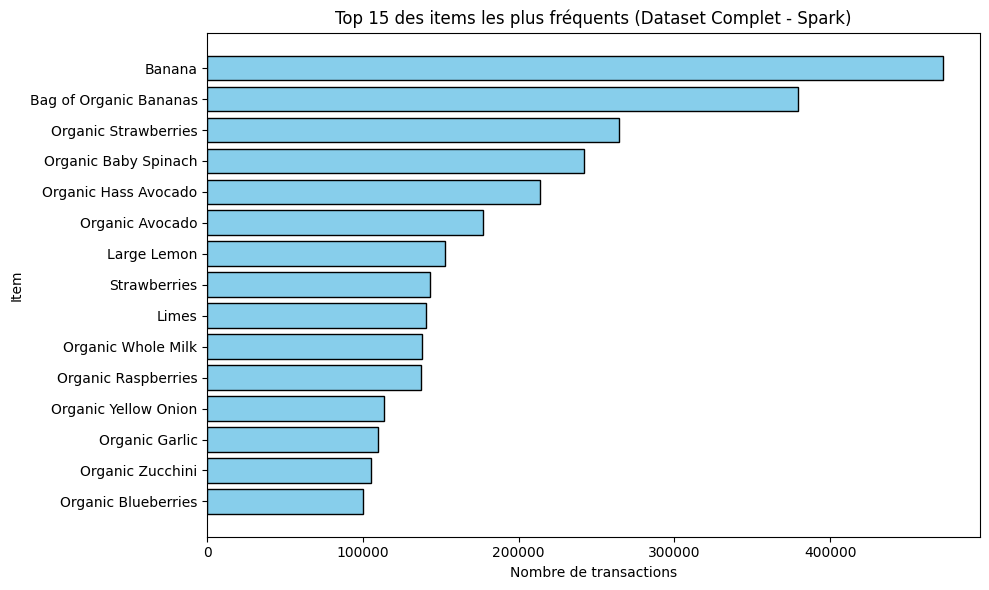

In [ ]:
import pyspark.sql.functions as F
import matplotlib.pyplot as plt

item_counts_df = clean_data.groupBy("product_name") \
                           .count() \
                           .withColumnRenamed("count", "Frequence")

total_transactions_count = transactions.count()

# . Add the Support column: Support = Frequence / Total Transactions
item_freq_support_df = item_counts_df.withColumn("Support", F.col("Frequence") / total_transactions_count) \
                                     .orderBy(F.desc("Frequence"))

# . Bring to Pandas and rename 'product_name' to 'Item' to match your teacher's format
frequences_items = item_freq_support_df.toPandas()
frequences_items = frequences_items.rename(columns={"product_name": "Item"})

# Display the full frequency & support table
display(frequences_items)

# 5. Plot the Top 15 horizontal bar chart using the correct "Item" column name
TOP_N = 15
top_items = frequences_items.head(TOP_N)

plt.figure(figsize=(10, 6))
plt.barh(top_items["Item"][::-1], top_items["Frequence"][::-1], color='skyblue', edgecolor='black')
plt.title(f"Top {TOP_N} des items les plus fréquents (Dataset Complet - Spark)")
plt.xlabel("Nombre de transactions")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

In [ ]:
from pyspark.ml.fpm import FPGrowth
import pandas as pd

# 1. Define your minimum support threshold (e.g., 0.05 or 5%)
MIN_SUPPORT = 0.005


fp = FPGrowth(itemsCol="items", minSupport=MIN_SUPPORT, minConfidence=0.5)
model = fp.fit(transactions)


spark_freq_itemsets = model.freqItemsets.toPandas()

total_transactions_count = transactions.count()
spark_freq_itemsets["support"] = spark_freq_itemsets["freq"] / total_transactions_count

spark_freq_itemsets["longueur"] = spark_freq_itemsets["items"].apply(len)

itemsets = spark_freq_itemsets.sort_values(
    ["longueur", "support"], ascending=[True, False]
).reset_index(drop=True)

if itemsets.empty:
    print("Aucun itemset fréquent. Essayez de diminuer MIN_SUPPORT.")
else:
    display(itemsets)

,items,freq,support,longueur
0,[Banana],472565,0.146993,1
1,[Bag of Organic Bananas],379450,0.118030,1
2,[Organic Strawberries],264683,0.082331,1
3,[Organic Baby Spinach],241921,0.075251,1
4,[Organic Hass Avocado],213584,0.066436,1
...,...,...,...,...
321,"[Organic Grape Tomatoes, Bag of Organic Bananas]",16650,0.005179,2
322,"[Organic Cucumber, Organic Strawberries]",16555,0.005150,2
323,"[Organic Zucchini, Organic Hass Avocado]",16464,0.005121,2
324,"[Large Lemon, Organic Strawberries]",16305,0.005072,2


In [17]:
# 1. Define your minimum confidence threshold
MIN_CONFIDENCE = 0.15

# 2. Check if your frequent itemsets dataframe is empty
if itemsets.empty:
    raise ValueError("Aucun itemset fréquent : diminuez MIN_SUPPORT.")

# 3. Extract association rules from our already-fitted Spark FPGrowth model
# (Note: We pass minConfidence directly to filter rules on the fly)
spark_fp = FPGrowth(itemsCol="items", minSupport=MIN_SUPPORT, minConfidence=MIN_CONFIDENCE)
spark_model = spark_fp.fit(transactions)
regles_spark = spark_model.associationRules.toPandas()

# 4. Rename Spark columns to match your teacher's exact mlxtend/Pandas format
# Spark uses: 'antecedent', 'consequent', 'confidence', 'lift', 'support'
# Mlxtend typically uses: 'antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift'
regles = regles_spark.rename(columns={
    "antecedent": "antecedents",
    "consequent": "consequents"
})

# 5. Display statistics and the top rules, just like your teacher's code
print("Nombre de règles générées :", len(regles))
display(regles.head())

# 6. Export the full rules table to Excel
regles.to_excel("liste_regles.xlsx")
print("Fichier 'liste_regles.xlsx' sauvegardé avec succès !")

Nombre de règles générées : 64


,antecedents,consequents,confidence,lift,support
0,[Seedless Red Grapes],[Banana],0.297428,2.023410,0.007650
1,[Organic Large Extra Fancy Fuji Apple],[Bag of Organic Bananas],0.310836,2.633546,0.007267
2,[Honeycrisp Apple],[Banana],0.356128,2.422752,0.008836
3,[Organic Cilantro],[Limes],0.252647,5.775753,0.005464
4,[Large Lemon],[Banana],0.267790,1.821783,0.012716


Fichier 'liste_regles.xlsx' sauvegardé avec succès !




## 11. Understanding Evaluation Metrics

| Metric | Definition | Interpretation |
|---|---|---|
| Support | \(P(A \cap B)\) | The joint frequency of A and B occurring together |
| Confidence | \(P(B\mid A)\) | The proportion of transactions containing A that also contain B |
| Lift | \(P(B\mid A)/P(B)\) | Measures the strength of the association compared to statistical independence |

### Lift Interpretation

- **Lift > 1:** Positive association. A and B occur together more often than expected under independence.
- **Lift = 1:** Statistical independence. The occurrence of A does not affect the probability of B.
- **Lift < 1:** Negative association. A and B occur together less often than expected under independence.

A high confidence value alone is not sufficient to establish a strong association, since the consequent (B) may already be very frequent across all transactions.

Therefore, **support, confidence, and lift should be analyzed together** to obtain a more reliable evaluation of association rules.



In [ ]:
regles_aff = regles.copy()

regles_aff["antecedents"] = regles_aff["antecedents"].apply(
    lambda x: ", ".join(sorted(map(str, x)))
)
regles_aff["consequents"] = regles_aff["consequents"].apply(
    lambda x: ", ".join(sorted(map(str, x)))
)

colonnes_regles = [
    "antecedents", "consequents", "support", "confidence", "lift"
]

print("Toutes les règles triées par Lift et Confiance :")
display(regles_aff[colonnes_regles].sort_values(
    ["lift", "confidence"], ascending=False
))

regles_interessantes = regles[
    (regles["support"] >= 0.005) &
    (regles["confidence"] >= 0.15) &
    (regles["lift"] > 1)
].copy()

print("Nombre de règles retenues :", len(regles_interessantes))

if not regles_interessantes.empty:
    display(regles_aff.loc[regles_interessantes.index, colonnes_regles]
            .sort_values(["lift", "confidence"], ascending=False))
else:
    print("Aucune règle ne remplit ces critères stricts. Essayez d'ajuster les seuils de support ou de confiance.")

Toutes les règles triées par Lift et Confiance :


,antecedents,consequents,support,confidence,lift
3,Organic Cilantro,Limes,0.005464,0.252647,5.775753
23,Organic Garlic,Organic Yellow Onion,0.006866,0.201069,5.698983
33,Organic Yellow Onion,Organic Garlic,0.006866,0.194603,5.698983
6,Large Lemon,Limes,0.008524,0.179507,4.103710
49,Limes,Large Lemon,0.008524,0.194863,4.103710
...,...,...,...,...,...
40,Apple Honeycrisp Organic,Banana,0.005422,0.205034,1.394853
61,Organic Blueberries,Banana,0.005904,0.189706,1.290577
34,Organic Zucchini,Banana,0.006009,0.184292,1.253741
19,Organic Garlic,Banana,0.005943,0.174051,1.184076


Nombre de règles retenues : 64


,antecedents,consequents,support,confidence,lift
3,Organic Cilantro,Limes,0.005464,0.252647,5.775753
23,Organic Garlic,Organic Yellow Onion,0.006866,0.201069,5.698983
33,Organic Yellow Onion,Organic Garlic,0.006866,0.194603,5.698983
6,Large Lemon,Limes,0.008524,0.179507,4.103710
49,Limes,Large Lemon,0.008524,0.194863,4.103710
...,...,...,...,...,...
40,Apple Honeycrisp Organic,Banana,0.005422,0.205034,1.394853
61,Organic Blueberries,Banana,0.005904,0.189706,1.290577
34,Organic Zucchini,Banana,0.006009,0.184292,1.253741
19,Organic Garlic,Banana,0.005943,0.174051,1.184076


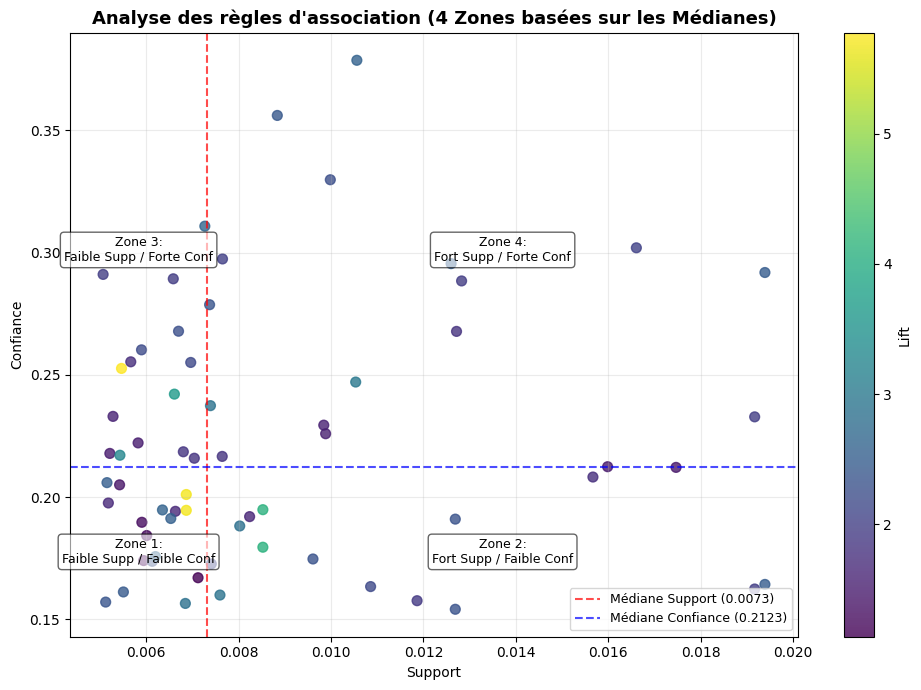

In [ ]:
import matplotlib.pyplot as plt

if not regles.empty:
    fig, ax = plt.subplots(figsize=(10, 7))

    med_supp = regles["support"].median()
    med_conf = regles["confidence"].median()

    sc = ax.scatter(
        regles["support"],
        regles["confidence"],
        s=50,
        c=regles["lift"],
        cmap="viridis",
        alpha=0.8
    )

    ax.axvline(med_supp, color='red', linestyle='--', alpha=0.7, label=f'Médiane Support ({med_supp:.4f})')
    ax.axhline(med_conf, color='blue', linestyle='--', alpha=0.7, label=f'Médiane Confiance ({med_conf:.4f})')

    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    ax.text(x_min + (med_supp - x_min)/2, y_min + (med_conf - y_min)/2, "Zone 1:\nFaible Supp / Faible Conf",
            ha='center', va='center', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.6))
    ax.text(x_max - (x_max - med_supp)/2, y_min + (med_conf - y_min)/2, "Zone 2:\nFort Supp / Faible Conf",
            ha='center', va='center', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.6))
    ax.text(x_min + (med_supp - x_min)/2, y_max - (y_max - med_conf)/2, "Zone 3:\nFaible Supp / Forte Conf",
            ha='center', va='center', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.6))
    ax.text(x_max - (x_max - med_supp)/2, y_max - (y_max - med_conf)/2, "Zone 4:\nFort Supp / Forte Conf",
            ha='center', va='center', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.6))

    ax.set_title("Analyse des règles d'association (4 Zones basées sur les Médianes)", fontsize=13, fontweight='bold')
    ax.set_xlabel("Support", fontsize=10)
    ax.set_ylabel("Confiance", fontsize=10)
    ax.grid(alpha=0.25)

    fig.colorbar(sc, ax=ax, label="Lift")
    ax.legend(loc='lower right', fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("Aucune règle générée. Diminuez le seuil de confiance ou le support minimal.")

In [ ]:
import pyspark.sql.functions as F
import pandas as pd

item_counts_df = clean_data.groupBy("product_name") \
                         .count() \
                         .withColumnRenamed("count", "Frequence")

total_transactions_count = transactions.count()

item_freq_support_df = item_counts_df.withColumn("Support", F.col("Frequence") / total_transactions_count) \
                                     .orderBy(F.desc("Frequence"))

frequences_items = item_freq_support_df.toPandas()
frequences_items = frequences_items.rename(columns={"product_name": "Item"})

frequences_items.to_csv(
    "items_frequents.csv", index=False, encoding="utf-8-sig"
)

print("Colonnes disponibles dans itemsets:", itemsets.columns)

itemsets_export = itemsets.copy()
if not itemsets_export.empty:
    target_col = "itemsets" if "itemsets" in itemsets_export.columns else "items"

    if target_col in itemsets_export.columns:
        itemsets_export["itemsets"] = itemsets_export[target_col].apply(
            lambda x: ", ".join(sorted(map(str, x)))
        )

    itemsets_export.to_csv(
        "itemsets_frequents.csv", index=False, encoding="utf-8-sig"
    )

#  Règles d'association export
regles_aff[colonnes_regles].to_csv(
    "regles_association.csv", index=False, encoding="utf-8-sig"
)

print("Export terminé avec succès !")

Colonnes disponibles dans itemsets: Index(['items', 'freq', 'support', 'longueur'], dtype='object')
Export terminé avec succès !


In [30]:
regles =  spark.read.option("header","True").option("inferSchema","True").csv("regles_association.csv")
regles.show(60,truncate=False)

+------------------------------------+----------------------+---------------------+-------------------+------------------+
|antecedents                         |consequents           |support              |confidence         |lift              |
+------------------------------------+----------------------+---------------------+-------------------+------------------+
|Seedless Red Grapes                 |Banana                |0.007650066534489377 |0.29742771106193083|2.0234097217790437|
|Organic Large Extra Fancy Fuji Apple|Bag of Organic Bananas|0.007267469891510523 |0.31083616044701656|2.633546160181689 |
|Honeycrisp Apple                    |Banana                |0.008836427181905108 |0.3561283205255174 |2.4227517448840947|
|Organic Cilantro                    |Limes                 |0.005463666694246804 |0.25264656809159425|5.775753468017493 |
|Large Lemon                         |Banana                |0.01271589493087443  |0.26778988189208486|1.8217826727708029|
|Large Lemon    